## Required Libraries

In [58]:
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
import os
import glob
import pandas as pd
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import numpy as np
import random
from sklearn.model_selection import train_test_split
import cv2
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

## Dataset

In [19]:
img = Image.open('../bloodcells_dataset/eosinophil/EO_27.jpg')
width, height = img.size

print(f'width of image: {width} pixels')
print(f'height of image: {height} pixels')

width of image: 360 pixels
height of image: 363 pixels


In [26]:
t = transforms.ToTensor()
tensor_img = t(img)

tensor_img

tensor([[[0.8510, 0.8471, 0.8471,  ..., 0.9608, 0.9725, 0.9804],
         [0.8471, 0.8471, 0.8471,  ..., 0.9765, 0.9843, 0.9922],
         [0.8471, 0.8471, 0.8471,  ..., 0.9922, 1.0000, 1.0000],
         ...,
         [0.8471, 0.8549, 0.8510,  ..., 0.8706, 0.9020, 0.9216],
         [0.8471, 0.8549, 0.8510,  ..., 0.8902, 0.9176, 0.9333],
         [0.8471, 0.8549, 0.8510,  ..., 0.9020, 0.9216, 0.9373]],

        [[0.7137, 0.7098, 0.7098,  ..., 0.8549, 0.8667, 0.8745],
         [0.7098, 0.7098, 0.7098,  ..., 0.8706, 0.8784, 0.8863],
         [0.7098, 0.7098, 0.7098,  ..., 0.8863, 0.8941, 0.8980],
         ...,
         [0.7294, 0.7255, 0.7216,  ..., 0.7490, 0.7804, 0.8078],
         [0.7294, 0.7255, 0.7216,  ..., 0.7686, 0.8000, 0.8196],
         [0.7294, 0.7255, 0.7216,  ..., 0.7843, 0.8039, 0.8275]],

        [[0.6902, 0.6863, 0.6863,  ..., 0.7490, 0.7529, 0.7569],
         [0.6863, 0.6863, 0.6863,  ..., 0.7647, 0.7647, 0.7725],
         [0.6863, 0.6863, 0.6863,  ..., 0.7804, 0.7804, 0.

In [28]:
tensor_img.shape

torch.Size([3, 363, 360])

In [20]:
dataset = datasets.ImageFolder(root='../bloodcells_dataset')
print(f"Number of images in dataset: {len(dataset)}")
print(f"Number of classes: {dataset.classes}")
print(f"Mapping classes to numbers: {dataset.class_to_idx}")

Number of images in dataset: 17092
Number of classes: ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']
Mapping classes to numbers: {'basophil': 0, 'eosinophil': 1, 'erythroblast': 2, 'ig': 3, 'lymphocyte': 4, 'monocyte': 5, 'neutrophil': 6, 'platelet': 7}


In [39]:
targets = dataset.targets

class_counts = Counter(targets)

print("data balance status")
for class_idx, count in class_counts.items():
    class_name = dataset.classes[class_idx]
    percentage = (count / len(dataset)) * 100
    print(f"class '{class_name}' (cls {class_idx}): {count} images ({percentage:.2f}%)")


data balance status
class 'basophil' (cls 0): 1218 images (7.13%)
class 'eosinophil' (cls 1): 3117 images (18.24%)
class 'erythroblast' (cls 2): 1551 images (9.07%)
class 'ig' (cls 3): 2895 images (16.94%)
class 'lymphocyte' (cls 4): 1214 images (7.10%)
class 'monocyte' (cls 5): 1420 images (8.31%)
class 'neutrophil' (cls 6): 3329 images (19.48%)
class 'platelet' (cls 7): 2348 images (13.74%)


The dataset is imbalance.

In [35]:
dataset_dir = '../bloodcells_dataset' 
base_dir = os.getcwd() 
data = []

class_names = sorted(os.listdir(dataset_dir))

for class_name in class_names:
    class_path = os.path.join(dataset_dir, class_name)
    
    if os.path.isdir(class_path):

        extensions = ('*.jpg', '*.jpeg', '*.png', '*.bmp')
        image_paths = []
        

        for ext in extensions:
            image_paths.extend(glob.glob(os.path.join(class_path, ext)))
            image_paths.extend(glob.glob(os.path.join(class_path, ext.upper())))
        
        image_paths = list(set(image_paths))
        
        for img_path in image_paths:

            relative_img_path = os.path.relpath(img_path, start=base_dir)

            relative_img_path = relative_img_path.replace('\\', '/')
            
            data.append({
                'image_path': relative_img_path,
                'class_name': class_name
            })

df = pd.DataFrame(data)

df['class_id'] = df['class_name'].astype('category').cat.codes

csv_output_path = 'dataset_info.csv'
df.to_csv(csv_output_path, index=False, encoding='utf-8')

In [36]:
df

,image_path,class_name,class_id
0,../bloodcells_dataset/basophil/BA_317405.jpg,basophil,0
1,../bloodcells_dataset/basophil/BA_835645.jpg,basophil,0
2,../bloodcells_dataset/basophil/BA_566824.jpg,basophil,0
3,../bloodcells_dataset/basophil/BA_383453.jpg,basophil,0
4,../bloodcells_dataset/basophil/BA_767164.jpg,basophil,0
...,...,...,...
17087,../bloodcells_dataset/platelet/PLATELET_890075...,platelet,7
17088,../bloodcells_dataset/platelet/PLATELET_610485...,platelet,7
17089,../bloodcells_dataset/platelet/PLATELET_140323...,platelet,7
17090,../bloodcells_dataset/platelet/PLATELET_753131...,platelet,7


In [44]:
df = pd.read_csv('dataset_info.csv')

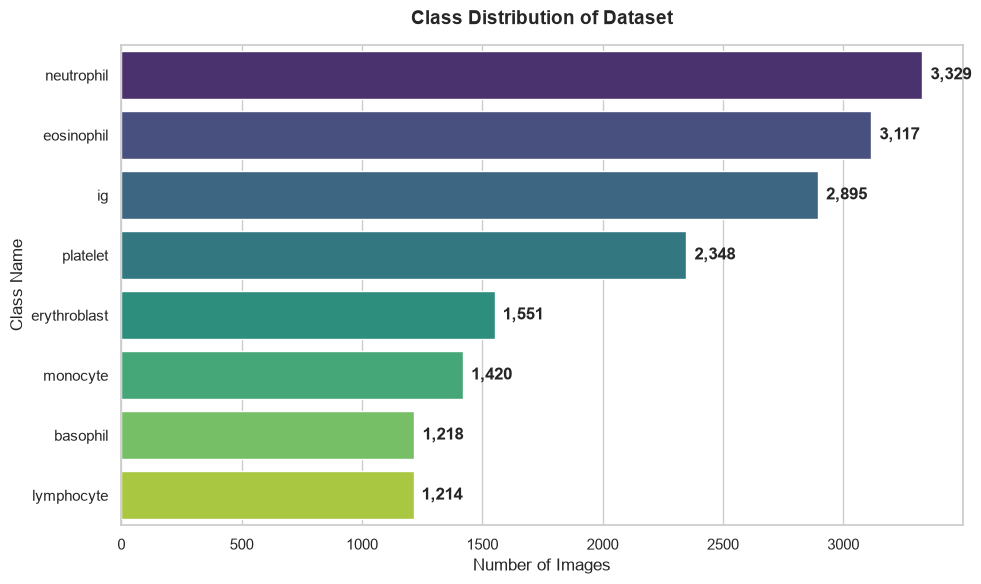

In [42]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

class_counts = df['class_name'].value_counts()

ax = sns.barplot(
    x=class_counts.values, 
    y=class_counts.index, 
    palette="viridis",
    hue=class_counts.index,
    legend=False
)

for i, v in enumerate(class_counts.values):
    ax.text(v + (max(class_counts.values) * 0.01), i, f"{v:,}", va='center', fontweight='bold')

plt.title("Class Distribution of Dataset", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Number of Images", fontsize=12)
plt.ylabel("Class Name", fontsize=12)

plt.tight_layout()
plt.savefig('dataset_balance.png', dpi=300)
plt.show()


To address the class imbalance observed during EDA and prevent the model from bias towards dominant classes, we will implement a weighted loss function. By applying class-specific weights to the loss function, the network will assign higher penalty to misclassifications of minority classes.

Extracting image dimensions...


100%|██████████| 17092/17092 [00:01<00:00, 11121.81it/s]


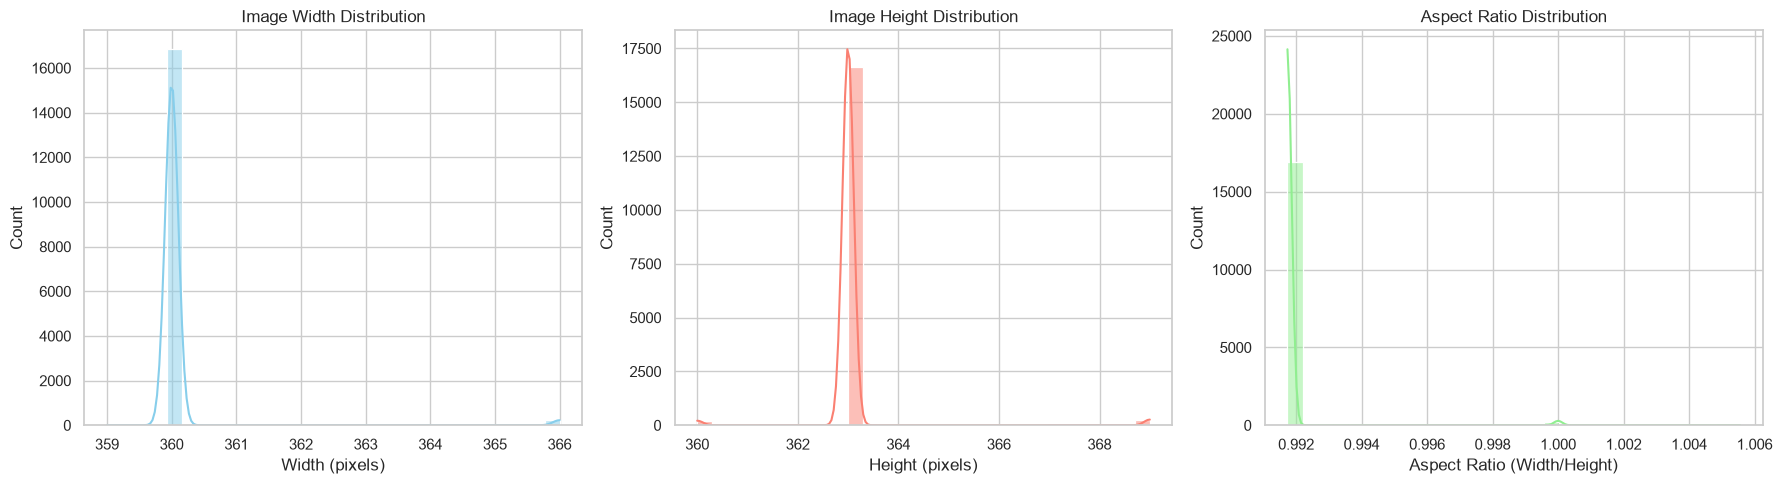

Dimension statistics:
              width        height  aspect_ratio
count  17092.000000  17092.000000  17092.000000
mean     360.087877    363.052247      0.991836
std        0.720570      0.793836      0.000897
min      359.000000    360.000000      0.991736
25%      360.000000    363.000000      0.991736
50%      360.000000    363.000000      0.991736
75%      360.000000    363.000000      0.991736
max      366.000000    369.000000      1.005556


In [45]:
widths = []
heights = []
aspect_ratios = []

print("Extracting image dimensions...")

for path in tqdm(df['image_path']):
    try:
        with Image.open(path) as img:
            w, h = img.size
            widths.append(w)
            heights.append(h)
            aspect_ratios.append(w / h)
    except Exception as e:
        widths.append(None)
        heights.append(None)
        aspect_ratios.append(None)

df['width'] = widths
df['height'] = heights
df['aspect_ratio'] = aspect_ratios

df = df.dropna()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['width'], bins=30, ax=axes[0], color='skyblue', kde=True)
axes[0].set_title('Image Width Distribution')
axes[0].set_xlabel('Width (pixels)')

sns.histplot(df['height'], bins=30, ax=axes[1], color='salmon', kde=True)
axes[1].set_title('Image Height Distribution')
axes[1].set_xlabel('Height (pixels)')

sns.histplot(df['aspect_ratio'], bins=30, ax=axes[2], color='lightgreen', kde=True)
axes[2].set_title('Aspect Ratio Distribution')
axes[2].set_xlabel('Aspect Ratio (Width/Height)')

plt.tight_layout()
plt.savefig('image_dimensions_eda.png', dpi=300)
plt.show()

print("Dimension statistics:")
print(df[['width', 'height', 'aspect_ratio']].describe())


best size for transform image sizes is (360, 360)

In [46]:
corrupted_files = []

print("Scanning for corrupted images...")
for idx, row in tqdm(df.iterrows(), total=len(df)):
    path = row['image_path']
    try:
        with Image.open(path) as img:
            img.verify()
    except Exception as e:
        print(f"Corrupted file found: {path} | Error: {e}")
        corrupted_files.append(path)

if len(corrupted_files) == 0:
    print("All images are verified and clean!")
else:
    print(f"Found {len(corrupted_files)} corrupted files. Consider removing them.")


Scanning for corrupted images...


100%|██████████| 17092/17092 [00:02<00:00, 8487.01it/s]

All images are verified and clean!


opening some random images from dataset from each class.

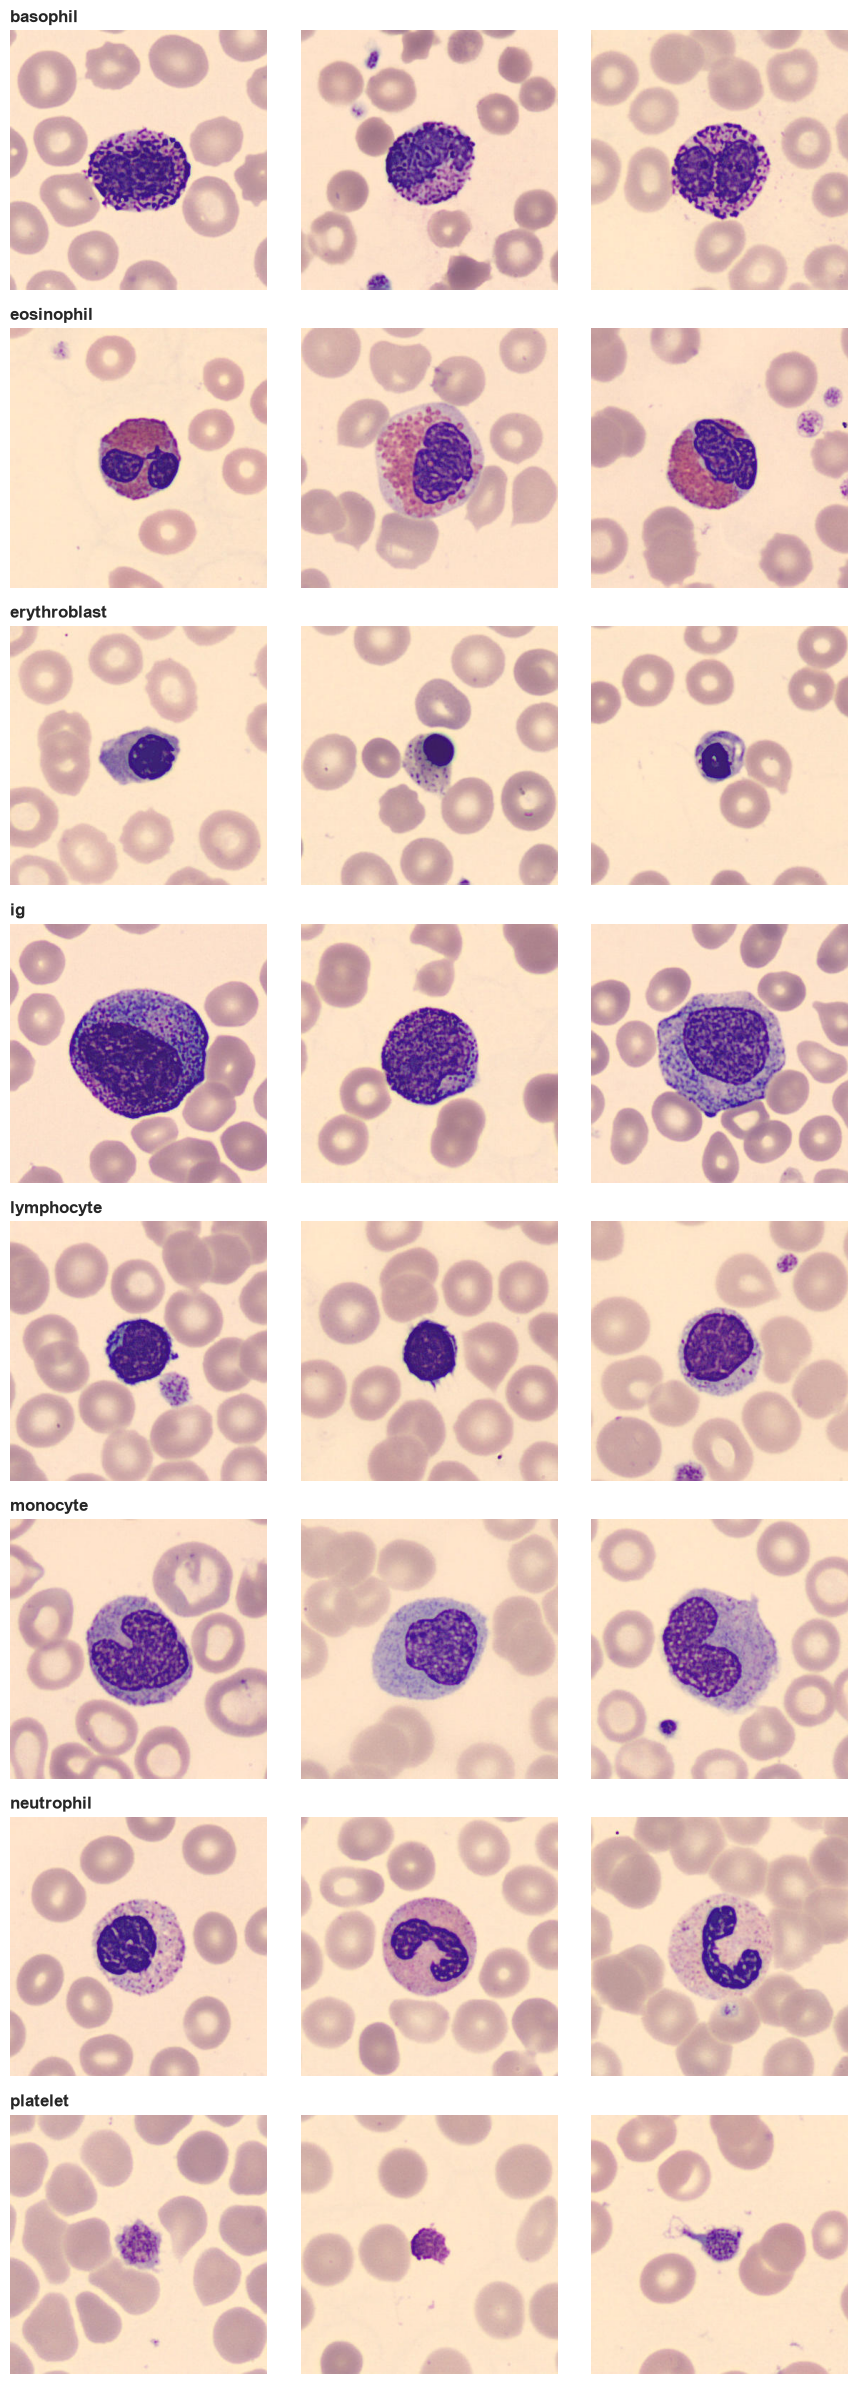

In [50]:
classes = df['class_name'].unique()
num_classes = len(classes)
samples_per_class = 3 

fig, axes = plt.subplots(num_classes, samples_per_class, figsize=(3 * samples_per_class, 3 * num_classes))

for i, class_name in enumerate(classes):
    class_df = df[df['class_name'] == class_name]
    sample_size = min(samples_per_class, len(class_df))
    sampled_paths = random.sample(class_df['image_path'].tolist(), sample_size)
    
    for j in range(samples_per_class):
        ax = axes[i, j] if num_classes > 1 else axes[j]
        if j < len(sampled_paths):
            img = Image.open(sampled_paths[j]).convert('RGB')
            ax.imshow(img)
            ax.axis('off')
            if j == 0:
                ax.set_title(class_name, fontsize=12, fontweight='bold', loc='left')
        else:
            ax.axis('off')

plt.tight_layout()
plt.savefig('dataset_class_samples.png', dpi=300)
plt.show()


splitting the dataset into train(80%), valid(10%), test(10%). 

In [52]:
train_df, temp_df = train_test_split(
    df, 
    test_size=0.2, 
    random_state=42, 
    stratify=df['class_id']
)

val_df, test_df = train_test_split(
    temp_df, 
    test_size=0.5, 
    random_state=42, 
    stratify=temp_df['class_id']
)

print(f"Dataset split completed successfully:")
print(f" - Train samples: {len(train_df)}")
print(f" - Validation samples: {len(val_df)}")
print(f" - Test samples: {len(test_df)}\n")

train_df.to_csv('train_split.csv', index=False)
val_df.to_csv('val_split.csv', index=False)
test_df.to_csv('test_split.csv', index=False)


Dataset split completed successfully:
 - Train samples: 13673
 - Validation samples: 1709
 - Test samples: 1710



In [54]:
train_df = pd.read_csv('train_split.csv')
val_df = pd.read_csv('val_split.csv')
test_df = pd.read_csv('test_split.csv')

In [55]:
pixel_sum = np.zeros(3)
pixel_squared_sum = np.zeros(3)
total_pixels = 0

print("Calculating exact Mean and Std on the Train Set...")
for path in tqdm(train_df['image_path']):
    try:
        with Image.open(path).convert('RGB') as img:
            img = img.resize((224, 224))
            arr = np.array(img) / 255.0 
            
            pixels = arr.reshape(-1, 3)
            
            pixel_sum += pixels.sum(axis=0)
            pixel_squared_sum += (pixels ** 2).sum(axis=0)
            total_pixels += pixels.shape[0]
    except Exception as e:
        continue

train_mean = pixel_sum / total_pixels
train_std = np.sqrt((pixel_squared_sum / total_pixels) - (train_mean ** 2))

print(f"Mean: {train_mean.tolist()}")
print(f"Std:  {train_std.tolist()}")

Calculating exact Mean and Std on the Train Set...


100%|██████████| 13673/13673 [00:45<00:00, 301.01it/s]

Mean: [0.8738403271227945, 0.7486465899118838, 0.7215444216680992]
Std:  [0.15869203339064175, 0.185724253225529, 0.07973004670164234]


Analyzing color distributions...


100%|██████████| 500/500 [00:00<00:00, 974.07it/s] 


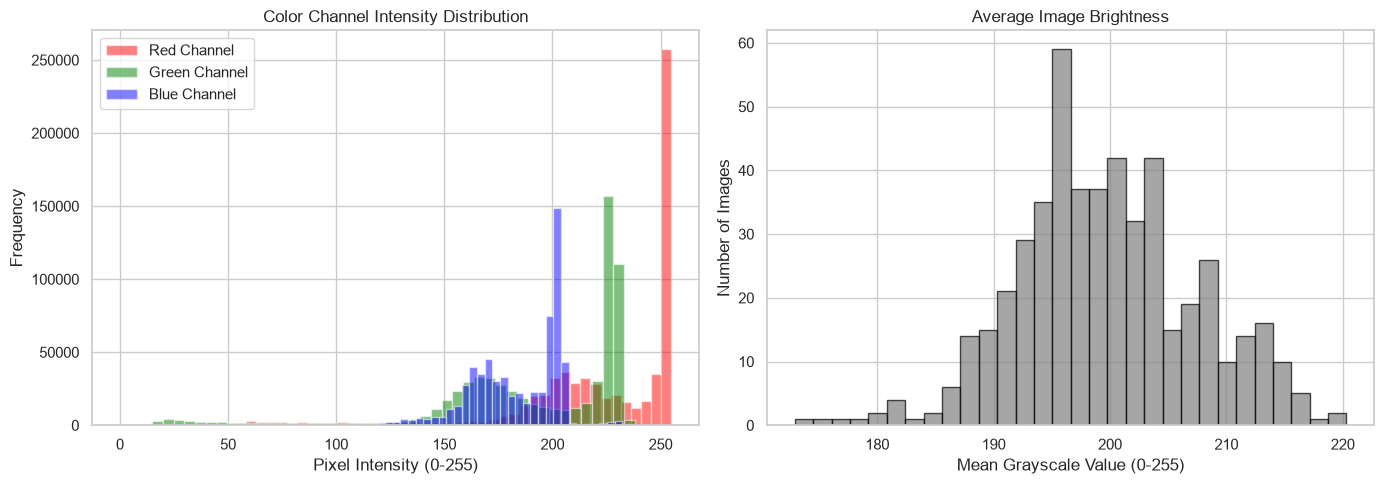

In [57]:
sampled_paths = train_df['image_path'].sample(n=min(500, len(train_df)), random_state=42)

r_vals, g_vals, b_vals = [], [], []
brightness_vals = []

print("Analyzing color distributions...")
for path in tqdm(sampled_paths):
    try:
        img = cv2.imread(path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        r_vals.extend(img[:, :, 0].flatten()[::100])
        g_vals.extend(img[:, :, 1].flatten()[::100])
        b_vals.extend(img[:, :, 2].flatten()[::100])
        
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        brightness_vals.append(gray.mean())
    except Exception:
        continue

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.hist(r_vals, bins=50, color='red', alpha=0.5, label='Red Channel')
plt.hist(g_vals, bins=50, color='green', alpha=0.5, label='Green Channel')
plt.hist(b_vals, bins=50, color='blue', alpha=0.5, label='Blue Channel')
plt.title('Color Channel Intensity Distribution')
plt.xlabel('Pixel Intensity (0-255)')
plt.ylabel('Frequency')
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(brightness_vals, bins=30, color='gray', edgecolor='black', alpha=0.7)
plt.title('Average Image Brightness')
plt.xlabel('Mean Grayscale Value (0-255)')
plt.ylabel('Number of Images')

plt.tight_layout()
plt.savefig('color_brightness_analysis.png', dpi=300)
plt.show()


### Color and Brightness Distribution Analysis

* **Gaussian-like Luminance:** The overall brightness (luminance) distribution exhibits a balanced, Gaussian-like shape, indicating consistent exposure across the dataset without extreme under-exposure (pure dark) or over-exposure (pure white) issues.
* **Asymmetric Channel Intensities:** While all three color channels follow a similar trend, they exhibit distinct sharp peaks at high-intensity values. Specifically, the Blue channel peaks around 200, the Green channel near 225, and the Red channel shows a massive spike close to 250.
* **Dominant Red Peak:** The Red channel spike is significantly higher than all other channels. In blood smear microscopy, this prominent high-intensity saturation represents the bright, pinkish-white background of the slides, where light passes through with minimal absorption.

**Preprocessing & Augmentation Decision:**
The consistent Gaussian brightness suggests that global illumination correction (like CLAHE) may not be strictly necessary. However, the strong color bias (especially the dominant red/pink background) carries a risk: the model might overfit to the background staining variations rather than cellular structures. To mitigate this and force the network to focus on cellular morphology, we should incorporate **ColorJitter** (with moderate hue and saturation shifts) and occasional **RandomGrayscale** transformations during training.


100%|██████████| 1000/1000 [00:00<00:00, 1089.46it/s]


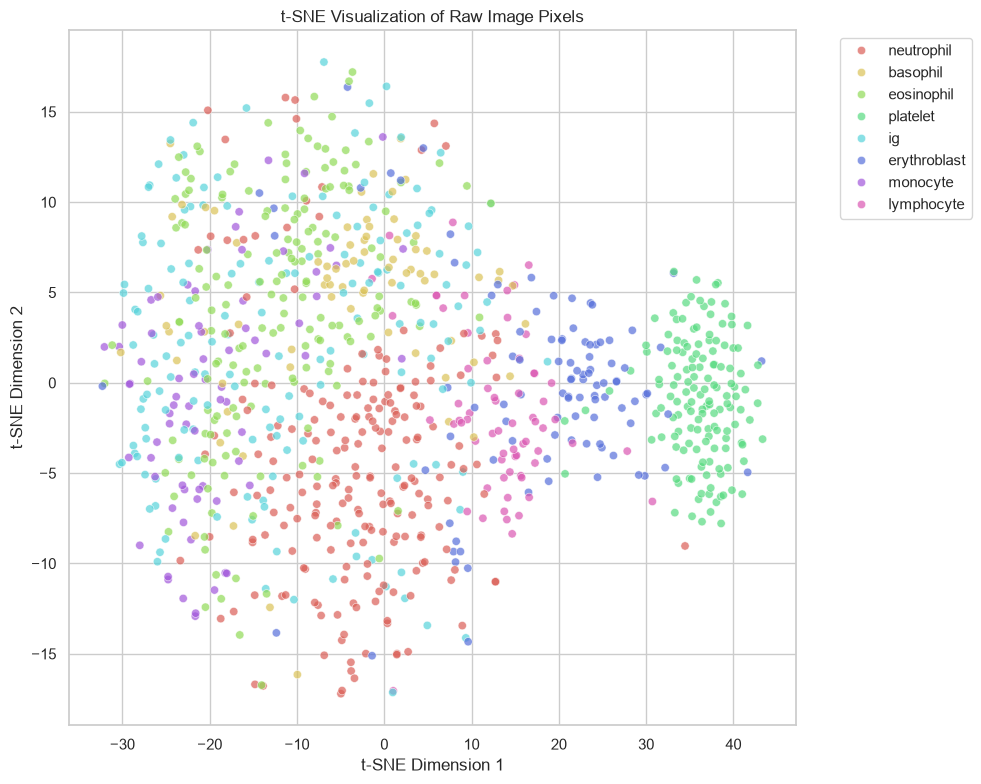

In [60]:
features = []
labels = []

sampled_df = train_df.sample(n=min(1000, len(train_df)), random_state=42)

for idx, row in tqdm(sampled_df.iterrows(), total=len(sampled_df)):
    try:
        with Image.open(row['image_path']).convert('L') as img:
            img = img.resize((32, 32))
            features.append(np.array(img).flatten() / 255.0)
            labels.append(row['class_name'])
    except Exception:
        continue

features = np.array(features)
labels = np.array(labels)

pca = PCA(n_components=min(50, len(features)))
pca_features = pca.fit_transform(features)

tsne = TSNE(n_components=2, perplexity=30, max_iter=1000, random_state=42)
tsne_results = tsne.fit_transform(pca_features)

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x=tsne_results[:, 0], y=tsne_results[:, 1],
    hue=labels,
    palette=sns.color_palette("hls", len(np.unique(labels))),
    legend="full",
    alpha=0.7
)
plt.title('t-SNE Visualization of Raw Image Pixels')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('tsne_dataset_clustering.png', dpi=300)
plt.show()


### Dimensionality Reduction Analysis (t-SNE Visualization)

* **Platelet Distinctness:** The `platelet` class forms a highly isolated and distinct cluster, showing clear visual separation from all other classes. This indicates that platelets possess unique low-level features (e.g., size, shape, and intensity) that make them easily distinguishable even without deep feature representation.
* **Central & Radial Distribution:** The `neutrophil` class is densely concentrated near the center of the feature space. The remaining classes are distributed radially around the neutrophils, forming an asymmetric, circular-like pattern. This suggests that neutrophils share intermediate morphological characteristics with multiple other cell types, creating a transition boundary in the raw pixel space.

**Architectural Decision:**
The separation of platelets suggests they will be classified with high accuracy. However, the close proximity and overlapping boundaries between neutrophils and surrounding classes indicate that a simple linear classifier will struggle.